# 14 · Stacks & Queues

**Stack** = **LIFO** (Last In, First Out), like a pile of plates: you add and remove at the **top**.
**Queue** = **FIFO** (First In, First Out), like a line at a ticket counter: you join at the **rear** and leave from the **front**.

| Structure | Operations |
|---|---|
| Stack | `push(x)`, `pop()`, `top()`, `size()`, `is_empty()` |
| Queue | `enqueue(x)`, `dequeue()`, `front()`, `rear()`, `size()`, `is_empty()` |
| Deque (double-ended queue) | insert/remove at **both** ends in O(1) |

**Topics covered**
1. Stack using a Python list
2. Queue using a list, and why `collections.deque` is better
3. Stack using a queue
4. Queue using two stacks
5. Stack and queue using linked lists
6. Valid parentheses
7. Min Stack (get the minimum in O(1))

## 1. Stack using a list

A Python list already works like a stack: `append()` pushes on the right end and `pop()` removes from the right end, both **O(1)**.

> 🐞 **Fixes:** the method was spelled `is_empy`; printing the stack object showed `<__main__.Stack object at 0x…>` (fixed with `__repr__`); and `pop` / `top` returned an error *string*. A string can be a legitimate stack value, so the caller couldn't tell an error from real data. Raising an `IndexError` is the standard Python way to signal "empty".

In [1]:
class Stack:
    def __init__(self):
        self.items = []

    def is_empty(self):
        return len(self.items) == 0

    def push(self, item):
        self.items.append(item)                  # add on top → O(1)

    def pop(self):
        if self.is_empty():
            raise IndexError("cannot pop: stack is empty")
        return self.items.pop()                  # remove from top → O(1)

    def top(self):
        if self.is_empty():
            raise IndexError("cannot peek: stack is empty")
        return self.items[-1]

    def size(self):
        return len(self.items)

    def __repr__(self):
        return f"Stack(bottom→top: {self.items})"

stack = Stack()
for x in (10, 30, 12, 14):
    stack.push(x)
print(stack)
print("popped:", stack.pop())                    # 14 (last in, first out)
print("popped:", stack.pop())                    # 12
print(stack)
print("top   :", stack.top())                    # 30
print("empty?:", stack.is_empty(), "| size:", stack.size())

Stack(bottom→top: [10, 30, 12, 14])
popped: 14
popped: 12
Stack(bottom→top: [10, 30])
top   : 30
empty?: False | size: 2


## 2. Queue using a list

`enqueue` = `append` (O(1)). `dequeue` = `pop(0)`, which must **shift every remaining element left**, so it costs **O(n)**. That is fine for learning but slow for big queues, so use `collections.deque` in real code (see the next cell).

In [2]:
class Queue:
    def __init__(self):
        self.items = []

    def is_empty(self):
        return len(self.items) == 0

    def enqueue(self, item):
        self.items.append(item)                  # join at the rear

    def dequeue(self):
        if self.is_empty():
            raise IndexError("cannot dequeue: queue is empty")
        return self.items.pop(0)                 # leave from the front (O(n) shift!)

    def front(self):
        if self.is_empty():
            raise IndexError("queue is empty")
        return self.items[0]

    def rear(self):
        if self.is_empty():
            raise IndexError("queue is empty")
        return self.items[-1]

    def size(self):
        return len(self.items)

    def __repr__(self):
        return f"Queue(front→rear: {self.items})"

queue = Queue()
for x in (10, 30, 12, 14):
    queue.enqueue(x)
print(queue)
print("dequeued:", queue.dequeue())              # 10 (first in, first out)
print("dequeued:", queue.dequeue())              # 30
print(queue)
print("front:", queue.front(), "| rear:", queue.rear(), "| size:", queue.size())

Queue(front→rear: [10, 30, 12, 14])
dequeued: 10
dequeued: 30
Queue(front→rear: [12, 14])
front: 12 | rear: 14 | size: 2


### Deque: a double-ended queue
`collections.deque` gives **O(1)** insertion and removal at **both** ends (`append`, `appendleft`, `pop`, `popleft`). It is the correct tool for queues, BFS, and sliding-window problems.

In [3]:
from collections import deque

d = deque()
d.append(10); d.append(20); d.append(30); d.append(40)
print(d)                                         # deque([10, 20, 30, 40])
d.appendleft(50); d.appendleft(60)
print(d)                                         # deque([60, 50, 10, 20, 30, 40])
d.pop()                                          # removes 40 from the right
print(d)
d.popleft()                                      # removes 60 from the left
print(d)

deque([10, 20, 30, 40])
deque([60, 50, 10, 20, 30, 40])
deque([60, 50, 10, 20, 30])
deque([50, 10, 20, 30])


## 3. Stack using a queue

**Goal:** `pop()` must return the **most recently pushed** element, but a queue only releases the **oldest** one.

**Trick (from the notes below):** on every `push(x)`
1. add `x` at the **end** of the queue
2. **rotate** the queue `n − 1` times (move the front element to the back), so `x` ends up at the **front**

Now the front of the queue is always the newest element, so `pop()` / `top()` just use the front.

```
push 10 → [10]
push 20 → [10, 20] → rotate once → [20, 10]
push 30 → [20, 10, 30] → rotate twice → [30, 20, 10]    pop() → 30 ✔
```

**push:** O(n) · **pop / top:** O(1)

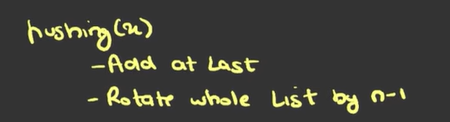

In [4]:
class StackUsingQueue:
    def __init__(self):
        self.queue = deque()

    def push(self, item):
        self.queue.append(item)                              # 1) add at the end
        for _ in range(len(self.queue) - 1):                 # 2) rotate the older n-1 elements behind it
            self.queue.append(self.queue.popleft())

    def pop(self):
        if not self.queue:
            raise IndexError("cannot pop: stack is empty")
        return self.queue.popleft()                          # front = newest

    def top(self):
        if not self.queue:
            raise IndexError("stack is empty")
        return self.queue[0]

    def size(self):
        return len(self.queue)

    def is_empty(self):
        return len(self.queue) == 0

suq = StackUsingQueue()
for x in (10, 20, 30, 40):
    suq.push(x)
print(suq.pop(), suq.pop(), suq.pop())                       # 40 30 20 (LIFO)
print("top:", suq.top())                                      # 10
suq.push(50)
print("top after push(50):", suq.top())                       # 50
print("pop:", suq.pop(), "| empty?", suq.is_empty(), "| size:", suq.size())

40 30 20
top: 10
top after push(50): 50
pop: 50 | empty? False | size: 1


> 🐞 The earlier test printed a leftover global variable `queue` (the `Queue` object from section 2) instead of the stack being tested, which produced confusing output like `<__main__.Queue object …>`. Fixed.

## 4. Queue using two stacks

**Goal:** `pop()` must return the **oldest** element, but a stack releases the **newest**.

### Approach A – keep `st1` always in queue order (from the notes)
On `push(x)`:
1. move **all** elements `st1 → st2` (this reverses them)
2. put `x` into `st1`
3. move everything back `st2 → st1`

Now the **top of `st1` is the oldest element**, so `pop()` / `peek()` are just `st1.pop()` / `st1[-1]`.

**push:** O(n) · **pop / peek:** O(1)

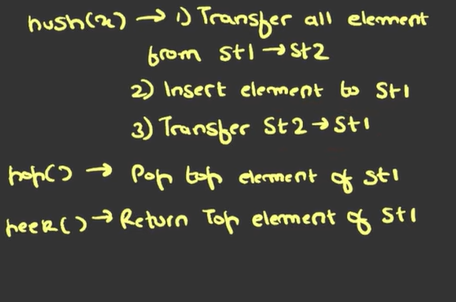

In [5]:
class QueueUsingTwoStacks:
    def __init__(self):
        self.st1 = []
        self.st2 = []

    def push(self, item):
        while self.st1:                          # 1) st1 -> st2
            self.st2.append(self.st1.pop())
        self.st1.append(item)                    # 2) insert the new element at the bottom
        while self.st2:                          # 3) st2 -> st1
            self.st1.append(self.st2.pop())

    def pop(self):
        if not self.st1:
            raise IndexError("queue is empty")
        return self.st1.pop()                    # top of st1 = oldest element

    def peek(self):
        if not self.st1:
            raise IndexError("queue is empty")
        return self.st1[-1]

    def is_empty(self):
        return not self.st1

q = QueueUsingTwoStacks()
for x in (10, 20, 30, 40):
    q.push(x)
print(q.pop(), q.pop())                          # 10 20 (FIFO)
print("peek:", q.peek())                         # 30

10 20
peek: 30


### Approach B – lazy transfer (amortised O(1))
Use an **input** stack for pushes and an **output** stack for pops. Only when the output stack is empty do we pour the input stack into it (this reverses the order once). Each element is moved at most once, so `push`, `pop` and `peek` are all **amortised O(1)**.

In [6]:
class QueueLazy:
    def __init__(self):
        self.inp, self.out = [], []

    def push(self, item):
        self.inp.append(item)                    # always O(1)

    def _shift(self):
        if not self.out:                         # refill only when needed
            while self.inp:
                self.out.append(self.inp.pop())

    def pop(self):
        self._shift()
        if not self.out:
            raise IndexError("queue is empty")
        return self.out.pop()

    def peek(self):
        self._shift()
        if not self.out:
            raise IndexError("queue is empty")
        return self.out[-1]

q = QueueLazy()
for x in (1, 2, 3):
    q.push(x)
print(q.pop())                                   # 1
q.push(4)
print(q.pop(), q.pop(), q.pop())                 # 2 3 4

1
2 3 4


## 5. Stack and queue using linked lists

A linked list gives a stack and queue with **no shifting and no fixed capacity**.

- **Stack:** keep only a `top` pointer. `push` links a new node in front of `top`; `pop` moves `top` to `top.next`. Both are O(1).
- **Queue:** keep a `front` pointer and a `rear` pointer. `push` attaches a node after `rear`; `pop` moves `front` forward. If the queue becomes empty, **reset `rear` to `None`** too.

In [7]:
class Node:
    def __init__(self, item):
        self.item = item
        self.next = None

class MyStack:
    def __init__(self):
        self.top = None                          # None means empty
        self.count = 0

    def push(self, item):
        node = Node(item)
        node.next = self.top                     # new node points to the old top
        self.top = node                          # new node becomes the top
        self.count += 1

    def pop(self):
        if self.top is None:
            raise IndexError("stack is empty")
        popped = self.top.item
        self.top = self.top.next
        self.count -= 1
        return popped

    def peek(self):
        if self.top is None:
            raise IndexError("stack is empty")
        return self.top.item

    def is_empty(self):
        return self.top is None

    def size(self):
        return self.count

s = MyStack()
for x in (10, 20, 30):
    s.push(x)
print(s.pop(), s.pop(), "| peek:", s.peek(), "| size:", s.size())      # 30 20 | peek: 10 | size: 1

30 20 | peek: 10 | size: 1


In [8]:
class MyQueue:
    def __init__(self):
        self.front = None
        self.rear = None
        self.count = 0

    def push(self, item):                        # enqueue at the rear
        node = Node(item)
        if self.rear is None:                    # empty queue: node is both front and rear
            self.front = self.rear = node
        else:
            self.rear.next = node
            self.rear = node
        self.count += 1

    def pop(self):                               # dequeue from the front
        if self.front is None:
            raise IndexError("queue is empty")
        popped = self.front.item
        self.front = self.front.next
        if self.front is None:                   # queue just became empty
            self.rear = None
        self.count -= 1
        return popped

    def peek(self):
        if self.front is None:
            raise IndexError("queue is empty")
        return self.front.item

    def is_empty(self):
        return self.front is None

    def size(self):
        return self.count

mq = MyQueue()
for x in (10, 20, 30):
    mq.push(x)
print(mq.pop(), mq.pop(), "| peek:", mq.peek(), "| size:", mq.size())  # 10 20 | peek: 30 | size: 1
mq.pop()
mq.push(99)                                      # works again after becoming empty
print(mq.peek(), mq.is_empty())                  # 99 False

10 20 | peek: 30 | size: 1
99 False


## 6. Valid parentheses

Given a string of `()[]{}`, decide whether the brackets are **balanced and correctly nested**.

**Idea:** an opening bracket must be closed by the **most recent unclosed** opening bracket, which is exactly what a stack gives us.
- opening bracket → **push**
- closing bracket → the stack must be non-empty **and** its top must be the matching opener, then **pop**
- at the end the stack must be **empty** (otherwise some brackets were never closed)

**Time:** O(n) · **Space:** O(n)

In [9]:
def is_valid_parentheses(s):
    stack = []
    pairs = {")": "(", "]": "[", "}": "{"}              # closer → its opener
    for bracket in s:
        if bracket in "([{":
            stack.append(bracket)
        else:
            if not stack or stack.pop() != pairs[bracket]:   # nothing to match, or wrong type
                return False
    return len(stack) == 0                               # leftovers mean unclosed brackets

tests = {"{([])}": True, "()[]{}": True, "(]": False, "([)]": False, "((": False, "))": False, "": True}
for text, expected in tests.items():
    assert is_valid_parentheses(text) == expected, text
    print(f"{text!r:10} → {is_valid_parentheses(text)}")

'{([])}'   → True
'()[]{}'   → True
'(]'       → False
'([)]'     → False
'(('       → False
'))'       → False
''         → True


## 7. Min Stack: `get_min()` in O(1)

Design a stack that supports `push`, `pop`, `top` and **`get_min`**, all in **O(1)**.

**Idea:** store, together with each value, **the minimum of the stack up to that point**: pairs `[value, min_so_far]`. The current minimum is always the second item of the top pair, and `pop()` automatically "forgets" the minimum that belonged to the removed element.

```
push 5 → [(5, 5)]
push 3 → [(5, 5), (3, 3)]
push 7 → [(5, 5), (3, 3), (7, 3)]     get_min() → 3
pop    → [(5, 5), (3, 3)]             get_min() → 3
pop    → [(5, 5)]                     get_min() → 5
```

> 🐞 **Fixes:** the earlier version used a global `items` list that was never defined, and wrote `min = min(...)` inside a function. That makes `min` a local variable that is read before it is assigned (`UnboundLocalError`), and it also hides the built-in `min()`. It's now a class, and `pop()` returns the **value** (not the `[value, min]` pair).

In [10]:
class MinStack:
    def __init__(self):
        self.items = []                          # each entry: (value, minimum so far)

    def push(self, val):
        if not self.items:
            self.items.append((val, val))
        else:
            self.items.append((val, min(val, self.items[-1][1])))

    def pop(self):
        if not self.items:
            raise IndexError("stack is empty")
        return self.items.pop()[0]

    def top(self):
        if not self.items:
            raise IndexError("stack is empty")
        return self.items[-1][0]

    def get_min(self):
        if not self.items:
            raise IndexError("stack is empty")
        return self.items[-1][1]

ms = MinStack()
for x in (5, 3, 7, 3, 8):
    ms.push(x)
print("min                  :", ms.get_min())     # 3
ms.pop(); ms.pop()                                # removes 8, then the second 3
print("min after two pops   :", ms.get_min())     # 3  (the first 3 is still in the stack)
ms.pop()                                          # removes 7
print("min after three pops :", ms.get_min())     # 3
ms.pop()                                          # removes the first 3 → only 5 is left
print("min after four pops  :", ms.get_min())     # 5
print("top                  :", ms.top())         # 5

min                  : 3
min after two pops   : 3
min after three pops : 3
min after four pops  : 5
top                  : 5


---
### ✅ Key takeaways
- **Stack = LIFO** (`list.append` / `list.pop`), **Queue = FIFO** (`deque.append` / `deque.popleft`). Don't use `list.pop(0)` for queues.
- To simulate one structure with another, move elements so the **newest/oldest ends up where you can reach it**.
- Balanced-bracket problems are a stack problem: push openers, match closers.
- To track an aggregate (min, max) in O(1), **store it alongside each element**.